In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from predict_building_energy_usage import process_data_and_features, clean_data
import numpy as np

In [3]:
energy=pd.read_csv('Energy_Usage_2010_20261010.csv', dtype={'AVERAGE HOUSESIZE': 'str', 'ZERO KWH ACCOUNTS': 'str', 'CENSUS BLOCK': 'str'})
energy=clean_data(energy)
predictors=['COMMUNITY AREA NAME', 'BUILDING TYPE', 'BUILDING_SUBTYPE', 'ELECTRICITY ACCOUNTS', 'GAS ACCOUNTS', 'TOTAL POPULATION', 'TOTAL UNITS', 'AVERAGE STORIES', 'AVERAGE BUILDING AGE', 'AVERAGE HOUSESIZE', 'OCCUPIED UNITS', 'OCCUPIED UNITS PERCENTAGE', 'RENTER-OCCUPIED HOUSING UNITS', 'RENTER-OCCUPIED HOUSING PERCENTAGE', 'OCCUPIED HOUSING UNITS']
categorical_predictors=['COMMUNITY AREA NAME', 'BUILDING TYPE', 'BUILDING_SUBTYPE']
to_predict = ['TOTAL KWH', 'TOTAL THERMS']

In [4]:
most_common_census_block=energy['CENSUS BLOCK'].value_counts().index[0]
energy[energy['CENSUS BLOCK'] == most_common_census_block][predictors]

,COMMUNITY AREA NAME,BUILDING TYPE,BUILDING_SUBTYPE,ELECTRICITY ACCOUNTS,GAS ACCOUNTS,TOTAL POPULATION,TOTAL UNITS,AVERAGE STORIES,AVERAGE BUILDING AGE,AVERAGE HOUSESIZE,OCCUPIED UNITS,OCCUPIED UNITS PERCENTAGE,RENTER-OCCUPIED HOUSING UNITS,RENTER-OCCUPIED HOUSING PERCENTAGE,OCCUPIED HOUSING UNITS
575,Bridgeport,Commercial,Multi < 7,NaN,5.0,136.0,47.0,3.00,97.00,3.16,43.0,0.9148,28.0,0.6509,43.0
11706,Bridgeport,Residential,Single Family,11.0,9.0,136.0,47.0,1.00,1.17,3.16,43.0,0.9148,28.0,0.6509,43.0
39106,Lower West Side,Commercial,Commercial,10.0,14.0,136.0,47.0,1.42,34.00,3.16,43.0,0.9148,28.0,0.6509,43.0
39107,Lower West Side,Commercial,Multi < 7,8.0,8.0,136.0,47.0,2.67,75.67,3.16,43.0,0.9148,28.0,0.6509,43.0
39108,Lower West Side,Residential,Multi < 7,45.0,49.0,136.0,47.0,2.00,107.78,3.16,43.0,0.9148,28.0,0.6509,43.0
39109,Lower West Side,Residential,Single Family,10.0,4.0,136.0,47.0,1.33,112.67,3.16,43.0,0.9148,28.0,0.6509,43.0
39568,McKinley Park,Commercial,Commercial,4.0,NaN,136.0,47.0,1.25,23.00,3.16,43.0,0.9148,28.0,0.6509,43.0
42449,Near West Side,Residential,Single Family,10.0,10.0,136.0,47.0,1.00,0.00,3.16,43.0,0.9148,28.0,0.6509,43.0


In [55]:
energy_nona=energy.dropna()
#which predictors are all the same within each census block
predictors_based_on_census_block=energy_nona.groupby('CENSUS BLOCK')[predictors].nunique().eq(1).all()
predictors_based_on_census_block[predictors_based_on_census_block==True].index

Index(['TOTAL POPULATION', 'TOTAL UNITS', 'AVERAGE HOUSESIZE',
       'OCCUPIED UNITS', 'OCCUPIED UNITS PERCENTAGE',
       'RENTER-OCCUPIED HOUSING UNITS', 'RENTER-OCCUPIED HOUSING PERCENTAGE',
       'OCCUPIED HOUSING UNITS'],
      dtype='str')

In [64]:
mean_energy_usage_by_census_block=energy_nona.groupby('CENSUS BLOCK')[to_predict].mean()
mean_energy_usage_by_census_block['TOTAL KWH'].describe()

count    2.894900e+04
mean     1.418718e+05
std      8.719111e+05
min      3.522000e+03
25%      6.178850e+04
50%      9.255200e+04
75%      1.361980e+05
max      1.167317e+08
Name: TOTAL KWH, dtype: float64

Text(0.5, 1.0, 'distribution of mean TOTAL KWH over census blocks')

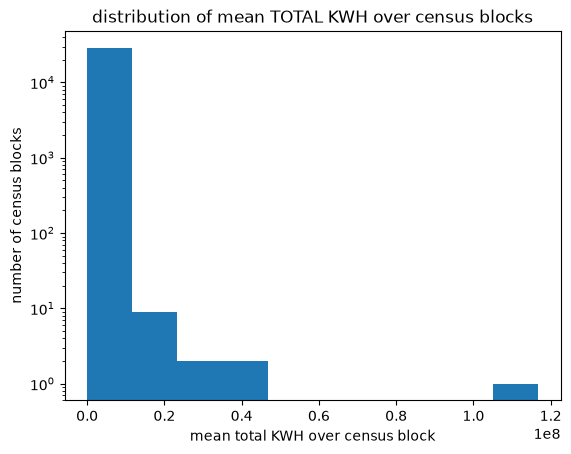

In [78]:
plt.hist(mean_energy_usage_by_census_block['TOTAL KWH'], log=True)
plt.xlabel('mean total KWH over census block')
plt.ylabel('number of census blocks')
plt.title('distribution of mean TOTAL KWH over census blocks')

In [73]:
#what's the outlier
outlier_value=mean_energy_usage_by_census_block[mean_energy_usage_by_census_block['TOTAL KWH']> 1e8]['TOTAL KWH']
outlier_value

CENSUS BLOCK
170313201001005    116731713.0
Name: TOTAL KWH, dtype: float64

In [75]:
energy[energy['TOTAL KWH']==outlier_value.values[0]]

,COMMUNITY AREA NAME,CENSUS BLOCK,BUILDING TYPE,BUILDING_SUBTYPE,KWH JANUARY 2010,KWH FEBRUARY 2010,KWH MARCH 2010,KWH APRIL 2010,KWH MAY 2010,KWH JUNE 2010,...,TOTAL POPULATION,TOTAL UNITS,AVERAGE STORIES,AVERAGE BUILDING AGE,AVERAGE HOUSESIZE,OCCUPIED UNITS,OCCUPIED UNITS PERCENTAGE,RENTER-OCCUPIED HOUSING UNITS,RENTER-OCCUPIED HOUSING PERCENTAGE,OCCUPIED HOUSING UNITS
38467,Loop,170313201001005,Commercial,Commercial,"10,135,384","9,513,220","7,169,960","7,137,167","8,842,112","10,428,173",...,859.0,629.0,35.5,70.5,1.79,480.0,0.7631,98.0,0.204,480.0


In [84]:
#find a community area name for the census blocks with the top energy usage
top_energy_usage_census_blocks = mean_energy_usage_by_census_block.nlargest(10, 'TOTAL KWH')
top_energy_usage_census_blocks.join(energy[['CENSUS BLOCK', 'COMMUNITY AREA NAME']].drop_duplicates().set_index('CENSUS BLOCK'), on='CENSUS BLOCK')

,TOTAL KWH,TOTAL THERMS,COMMUNITY AREA NAME
CENSUS BLOCK,,,
170313201001005,116731713.0,200225.0,Loop
170310104003006,44826788.0,1361212.0,Rogers Park
170313201003008,35433904.0,1431604.0,Loop
170318432002054,24606648.0,272177.0,Lower West Side
170310813003000,24334891.0,1086348.0,Near North Side
170318422001057,17051767.0,22669.5,Near North Side
170310812012003,14294467.0,593777.0,Near North Side
170310816001011,13713863.0,65990.0,Near North Side
170313204001010,13102583.0,1190689.0,Loop


Text(0.5, 1.0, 'TOTAL KWH vs TOTAL THERMS')

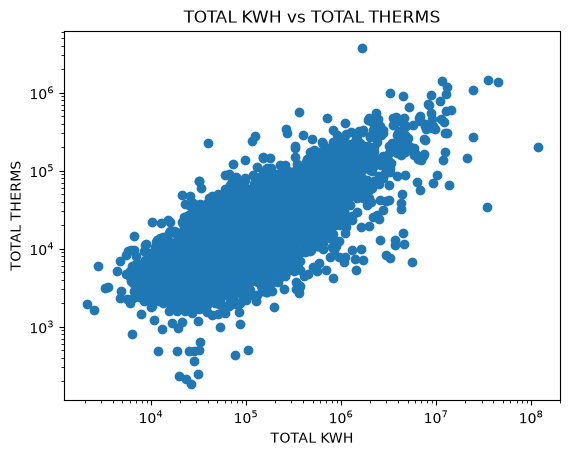

In [90]:
fig, ax = plt.subplots()
ax.scatter(energy_nona['TOTAL KWH'], energy_nona['TOTAL THERMS'])
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('TOTAL KWH')
ax.set_ylabel('TOTAL THERMS')
ax.set_title('TOTAL KWH vs TOTAL THERMS')